# Programmatically download and load the transactions data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import zipfile
import io

In [2]:
# URL to the zip file in the GitHub repository
url = "https://github.com/CapitalOneRecruiting/DS/raw/master/transactions.zip"

# Step 1: Programmatically download the zip file
response = requests.get(url)
if response.status_code == 200:
    # Step 2: Extract the transactions.txt file from transactions.zip
    with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
        with zip_file.open("transactions.txt") as data_file:
            # Step 3: Load the data file into a DataFrame
            transactions = pd.read_json(data_file, lines=True)
else:
    print("Failed to download the zip file. Check the URL or internet connection.")

## Structure of the data

In [3]:
# Number of records (rows) and fields (columns)
num_records = len(transactions)
num_fields = len(transactions.columns)
print(f"Number of records: {num_records}")
print(f"Number of fields: {num_fields}")

Number of records: 786363
Number of fields: 29


## Basic summary statistics

In [4]:
# Set pandas to display all columns
pd.set_option('display.max_columns', None)

# Now display the first 5 rows of the DataFrame
transactions.head(5)

,accountNumber,customerId,creditLimit,availableMoney,transactionDateTime,transactionAmount,merchantName,acqCountry,merchantCountryCode,posEntryMode,posConditionCode,merchantCategoryCode,currentExpDate,accountOpenDate,dateOfLastAddressChange,cardCVV,enteredCVV,cardLast4Digits,transactionType,echoBuffer,currentBalance,merchantCity,merchantState,merchantZip,cardPresent,posOnPremises,recurringAuthInd,expirationDateKeyInMatch,isFraud
0,737265056,737265056,5000,5000.0,2016-08-13T14:27:32,98.55,Uber,US,US,02,01,rideshare,06/2023,2015-03-14,2015-03-14,414,414,1803,PURCHASE,,0.0,,,,False,,,False,False
1,737265056,737265056,5000,5000.0,2016-10-11T05:05:54,74.51,AMC #191138,US,US,09,01,entertainment,02/2024,2015-03-14,2015-03-14,486,486,767,PURCHASE,,0.0,,,,True,,,False,False
2,737265056,737265056,5000,5000.0,2016-11-08T09:18:39,7.47,Play Store,US,US,09,01,mobileapps,08/2025,2015-03-14,2015-03-14,486,486,767,PURCHASE,,0.0,,,,False,,,False,False
3,737265056,737265056,5000,5000.0,2016-12-10T02:14:50,7.47,Play Store,US,US,09,01,mobileapps,08/2025,2015-03-14,2015-03-14,486,486,767,PURCHASE,,0.0,,,,False,,,False,False
4,830329091,830329091,5000,5000.0,2016-03-24T21:04:46,71.18,Tim Hortons #947751,US,US,02,01,fastfood,10/2029,2015-08-06,2015-08-06,885,885,3143,PURCHASE,,0.0,,,,True,,,False,False


## Replace empty strings, whitespace-only strings, and placeholders with NaN

In [5]:
transactions.replace(["", " ", "N/A", "NULL"], np.nan, inplace=True)

<ipython-input-5-66234b75ef4b>:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  transactions.replace(["", " ", "N/A", "NULL"], np.nan, inplace=True)


## Print columns' name

In [6]:
np.array(transactions.columns)

array(['accountNumber', 'customerId', 'creditLimit', 'availableMoney',
       'transactionDateTime', 'transactionAmount', 'merchantName',
       'acqCountry', 'merchantCountryCode', 'posEntryMode',
       'posConditionCode', 'merchantCategoryCode', 'currentExpDate',
       'accountOpenDate', 'dateOfLastAddressChange', 'cardCVV',
       'enteredCVV', 'cardLast4Digits', 'transactionType', 'echoBuffer',
       'currentBalance', 'merchantCity', 'merchantState', 'merchantZip',
       'cardPresent', 'posOnPremises', 'recurringAuthInd',
       'expirationDateKeyInMatch', 'isFraud'], dtype=object)

## Overview of missing values

In [7]:
missing_values = transactions.isnull().sum()
missing_percentage = (missing_values / len(transactions)) * 100

# Combine and display
missing_data_overview = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage Missing': missing_percentage
})
print(missing_data_overview.sort_values(by='Percentage Missing', ascending=False))

                          Missing Values  Percentage Missing
posOnPremises                     786363          100.000000
recurringAuthInd                  786363          100.000000
merchantState                     786363          100.000000
merchantZip                       786363          100.000000
echoBuffer                        786363          100.000000
merchantCity                      786363          100.000000
acqCountry                          4562            0.580139
posEntryMode                        4054            0.515538
merchantCountryCode                  724            0.092069
transactionType                      698            0.088763
posConditionCode                     409            0.052012
transactionDateTime                    0            0.000000
accountNumber                          0            0.000000
currentExpDate                         0            0.000000
merchantCategoryCode                   0            0.000000
merchantName            

## Drop columns with 100% missing values

In [8]:
transactions.drop(['echoBuffer','merchantCity','merchantState','merchantZip','posOnPremises','recurringAuthInd'], axis=1,inplace=True)

## Prtint columns' data types

In [9]:
print(transactions.dtypes)

accountNumber                 int64
customerId                    int64
creditLimit                   int64
availableMoney              float64
transactionDateTime          object
transactionAmount           float64
merchantName                 object
acqCountry                   object
merchantCountryCode          object
posEntryMode                 object
posConditionCode             object
merchantCategoryCode         object
currentExpDate               object
accountOpenDate              object
dateOfLastAddressChange      object
cardCVV                       int64
enteredCVV                    int64
cardLast4Digits               int64
transactionType              object
currentBalance              float64
cardPresent                    bool
expirationDateKeyInMatch       bool
isFraud                        bool
dtype: object


## There are 5000 unique customers in the dataset

In [10]:
transactions['customerId'].nunique()

5000

## Minimum, maximum, and unique values

In [11]:
# Numeric Columns
numeric_summary = transactions.describe(include=[np.number]).transpose()

# Categorical Columns
categorical_summary = transactions.describe(include=[object]).transpose()

# Boolean Columns
boolean_summary = transactions.select_dtypes(include=[bool]).apply(
    lambda col: pd.Series({
        'count': col.count(),
        'unique': col.nunique(),
        'top': col.mode()[0] if not col.mode().empty else None,
        'freq': col.sum()
    })
).transpose()

# Combined Summary (Optional)
print("Numeric Columns Summary:")
print(numeric_summary)

print("\nCategorical Columns Summary:")
print(categorical_summary)

print("\nBoolean Columns Summary:")
print(boolean_summary)

Numeric Columns Summary:
                      count          mean           std           min  \
accountNumber      786363.0  5.372326e+08  2.554211e+08  1.000881e+08   
customerId         786363.0  5.372326e+08  2.554211e+08  1.000881e+08   
creditLimit        786363.0  1.075946e+04  1.163617e+04  2.500000e+02   
availableMoney     786363.0  6.250725e+03  8.880784e+03 -1.005630e+03   
transactionAmount  786363.0  1.369858e+02  1.477256e+02  0.000000e+00   
cardCVV            786363.0  5.444673e+02  2.615242e+02  1.000000e+02   
enteredCVV         786363.0  5.441839e+02  2.615513e+02  0.000000e+00   
cardLast4Digits    786363.0  4.757418e+03  2.996584e+03  0.000000e+00   
currentBalance     786363.0  4.508739e+03  6.457442e+03  0.000000e+00   

                            25%           50%           75%           max  
accountNumber      3.301333e+08  5.074561e+08  7.676200e+08  9.993896e+08  
customerId         3.301333e+08  5.074561e+08  7.676200e+08  9.993896e+08  
creditLimit     

## Account and Customer Information
  ```accountNumber``` and ```customerId``` are unique identifiers.

In [12]:
account=transactions.accountNumber.unique()
customer=transactions['customerId'].unique()
comparison = account== customer
equal_arrays = comparison.all()
print(equal_arrays)

True


## Credit Limit Distribution
The values range from as low as \$250 to as high as \$50,000.

In [13]:
transactions.creditLimit.unique()

array([ 5000,  2500, 50000, 15000, 10000,   250,   500,  1000,  7500,
       20000])

The distribution of transactions across different credit limits, highlighting patterns related to fraud detection.

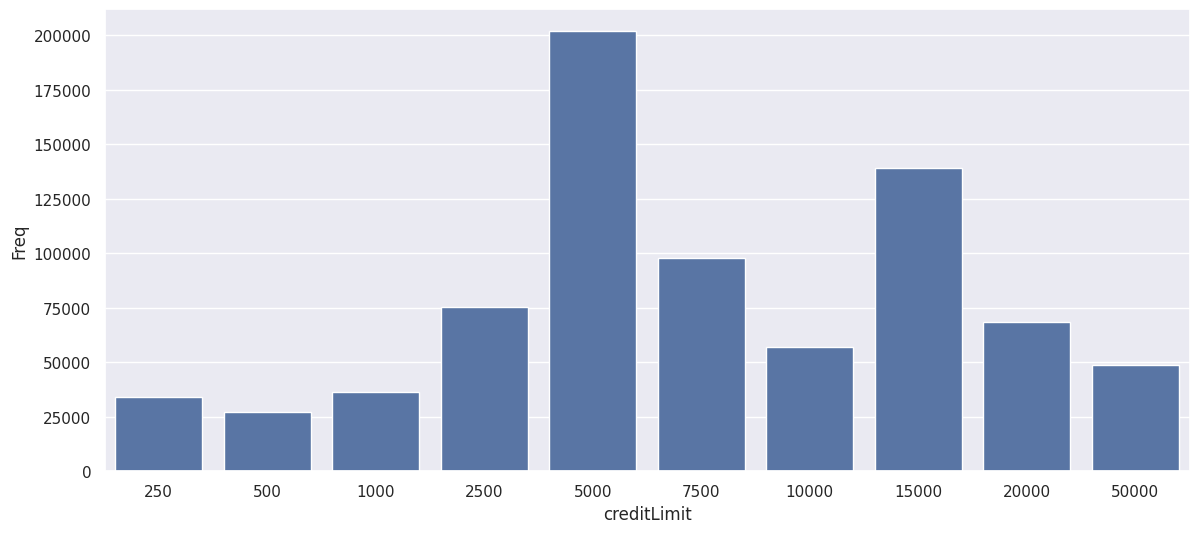

In [14]:
z=pd.DataFrame(transactions.groupby('creditLimit').count()['isFraud']).reset_index(drop=False)
z.columns=['creditLimit','Freq'] # rename columns
plt.figure(figsize=(14,6)) # adjust figure size
sns.set_theme() # set theme
ax = sns.barplot(x="creditLimit", y="Freq", data=z) # draw barplot

## Fraud



In [15]:
# Fraud percentage
fraud_percentage = transactions['isFraud'].mean() * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage:.2f}%")

# Compare transaction amounts for fraud and non-fraud
fraud_analysis = transactions.groupby('isFraud')['transactionAmount'].describe()
print(fraud_analysis)

Percentage of fraudulent transactions: 1.58%
            count        mean         std  min    25%     50%     75%      max
isFraud                                                                       
False    773946.0  135.570249  146.525305  0.0  33.19   86.76  189.39  2011.54
True      12417.0  225.215905  189.551393  0.0  86.00  176.98  311.46  1608.35


1.   Only 1.58% of the transactions in the dataset are fraudulent, meaning fraudulent transactions are rare, making this a highly imbalanced dataset.
2.   Fraudulent transactions tend to have higher amounts(\$225.22) than non-fraudulent transactions(\$135.57), indicating fraudsters may prefer targeting larger-value transactions.

In [16]:
# Convert transactionDateTime to datetime
transactions['transactionDateTime'] = pd.to_datetime(transactions['transactionDateTime'])

# Extract date and time components
transactions['transactionDate'] = transactions['transactionDateTime'].dt.date
transactions['transactionHour'] = transactions['transactionDateTime'].dt.hour

# Analyze transaction counts by hour
hourly_transactions = transactions.groupby('transactionHour')['isFraud'].mean()
print(hourly_transactions)

transactionHour
0     0.015645
1     0.014709
2     0.015190
3     0.016793
4     0.015907
5     0.015083
6     0.015858
7     0.015091
8     0.016595
9     0.016251
10    0.015707
11    0.016980
12    0.017353
13    0.018056
14    0.016032
15    0.016060
16    0.014777
17    0.015169
18    0.016099
19    0.014458
20    0.014758
21    0.016520
22    0.014497
23    0.015414
Name: isFraud, dtype: float64




*   The highest fraud proportion occurs at hour 13 (1 PM), with a value of 0.018056 (1.81%).
*   The lowest fraud proportion occurs at hour 19 (7 PM), with a value of 0.014458 (1.45%).

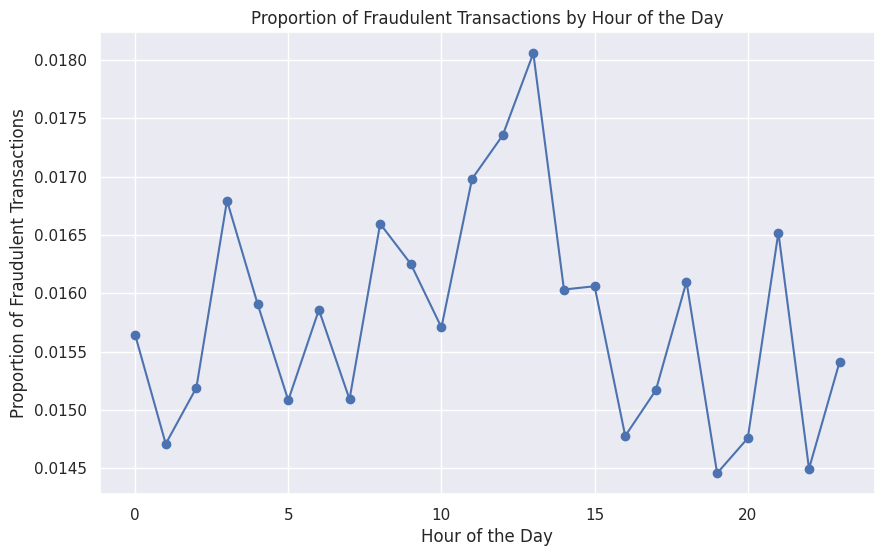

In [17]:
# Plot fraud rates by hour
transactions.groupby('transactionHour')['isFraud'].mean().plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Proportion of Fraudulent Transactions by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Proportion of Fraudulent Transactions')
plt.grid(True)
plt.show()

In [18]:
# list of merchant categories
transactions['merchantCategoryCode'].unique()

array(['rideshare', 'entertainment', 'mobileapps', 'fastfood',
       'food_delivery', 'auto', 'online_retail', 'gym', 'health',
       'personal care', 'food', 'fuel', 'online_subscriptions',
       'online_gifts', 'hotels', 'airline', 'furniture', 'subscriptions',
       'cable/phone'], dtype=object)

In [19]:
transactions['merchantCategoryCode'].nunique()

19

Top 3 categories are online, fastfood and entertainment in terms of the number of transactions.

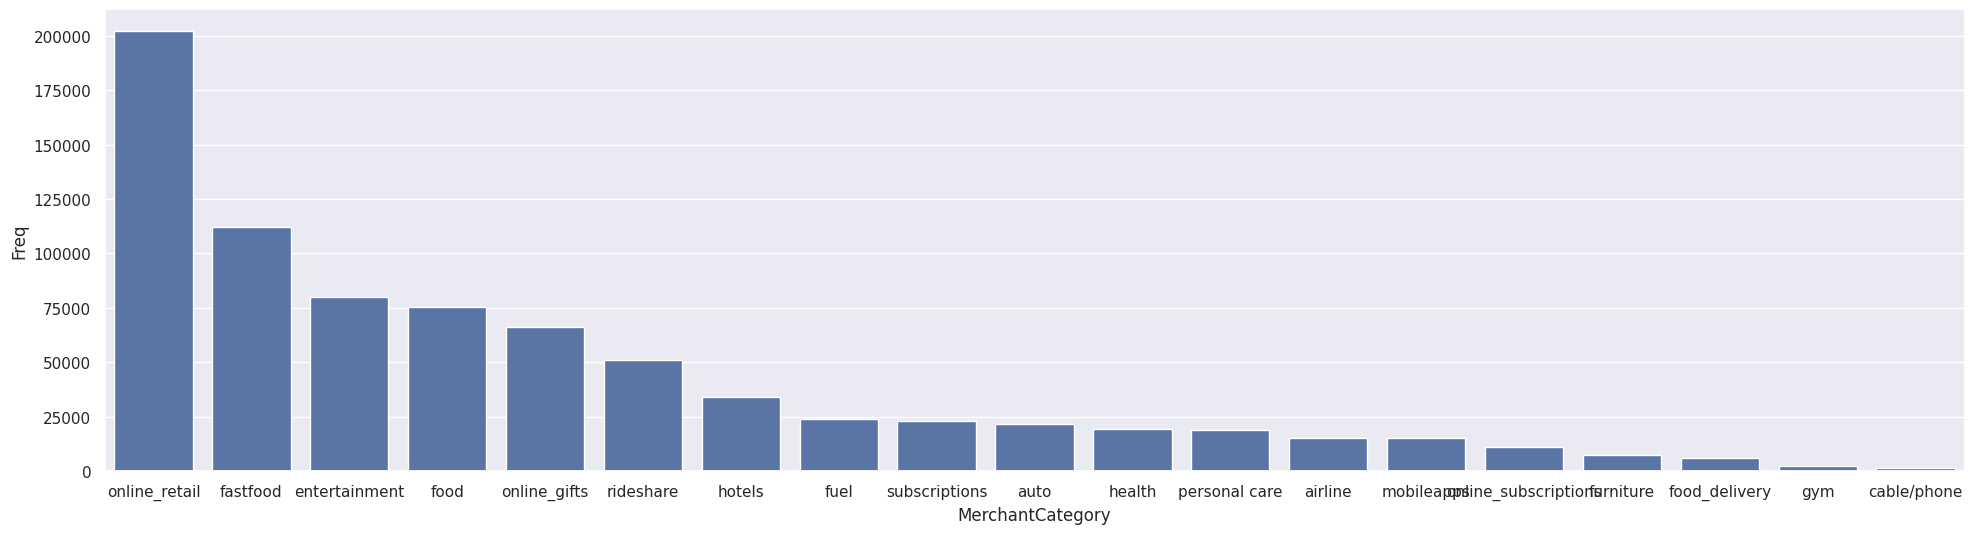

In [20]:
t=pd.DataFrame(transactions['merchantCategoryCode'].value_counts()).reset_index(drop=False)
t.columns=['MerchantCategory','Freq'] # rename columns
plt.figure(figsize=(24,6)) # adjust figure size
sns.set_theme() # set theme
ax = sns.barplot(x="MerchantCategory", y="Freq", data=t) # draw barplot

1. The highest fraud rate (3.46%) suggests airline-related transactions are a common target for fraud.

2. Categories like 'online_retail' and 'online_gifts' have higher fraud rates, reflecting the vulnerabilities of e-commerce platforms.

1. Canadian transactions have the highest fraud rate (2.31%), suggesting additional scrutiny for cross-border transactions from Canada.

2. Transactions in Mexico (2.04%) and Puerto Rico (1.73%) also show elevated fraud rates, likely due to weaker regulatory oversight or cross-border fraud risks.

3. The US has the lowest fraud rate (1.57%), likely due to stronger fraud detection systems and monitoring practices.

In [21]:
# Top merchant categories by fraud rate
fraud_by_category = transactions.groupby('merchantCategoryCode')['isFraud'].mean().sort_values(ascending=False)
print(fraud_by_category.head(10))

# Fraud by country
fraud_by_country = transactions.groupby('merchantCountryCode')['isFraud'].mean()
print(fraud_by_country.sort_values(ascending=False))

merchantCategoryCode
airline          0.034648
rideshare        0.024875
online_retail    0.024427
online_gifts     0.024246
furniture        0.013859
food             0.013432
auto             0.012609
entertainment    0.011998
fastfood         0.009577
subscriptions    0.009432
Name: isFraud, dtype: float64
merchantCountryCode
CAN    0.023083
MEX    0.020363
PR     0.017319
US     0.015656
Name: isFraud, dtype: float64


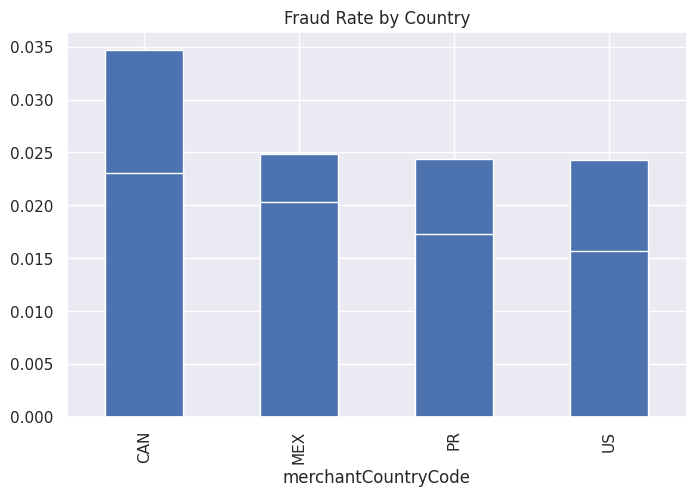

In [22]:
# Merchant fraud rates
fraud_by_category.head(10).plot(kind='bar', figsize=(10, 6), title='Fraud Rate by Merchant Category')

# Fraud rates by country
fraud_by_country.plot(kind='bar', figsize=(8, 5), title='Fraud Rate by Country')
plt.show()

1. Higher Fraud in Non-Card-Present Transactions.

2. Higher Fraud for Mismatched CVVs

In [23]:
# Fraud rate by cardPresent
fraud_by_card_present = transactions.groupby('cardPresent')['isFraud'].mean()
print(fraud_by_card_present)

# CVV match/mismatch fraud rates
transactions['cvv_mismatch'] = transactions['cardCVV'] != transactions['enteredCVV']
fraud_by_cvv_mismatch = transactions.groupby('cvv_mismatch')['isFraud'].mean()
print(fraud_by_cvv_mismatch)

cardPresent
False    0.020674
True     0.009791
Name: isFraud, dtype: float64
cvv_mismatch
False    0.015672
True     0.028938
Name: isFraud, dtype: float64


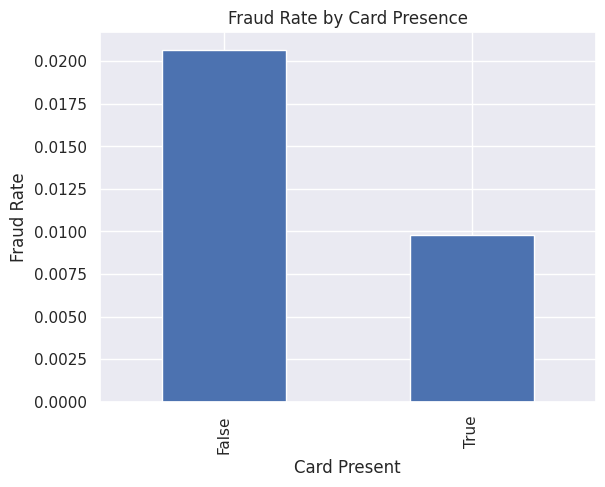

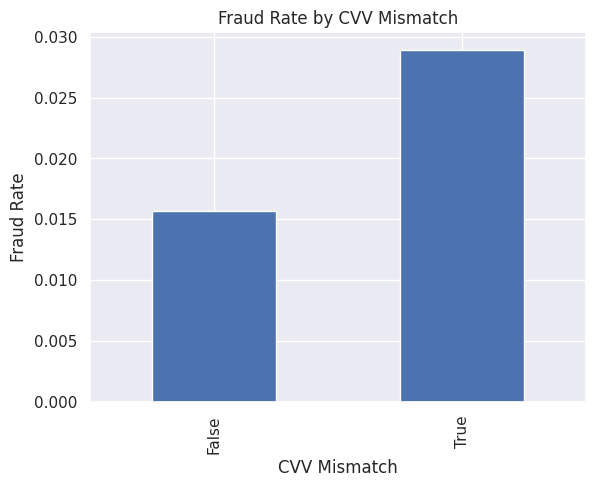

In [24]:
# Bar chart for cardPresent fraud rates
fraud_by_card_present.plot(kind='bar', title='Fraud Rate by Card Presence', ylabel='Fraud Rate', xlabel='Card Present')
plt.show()

# Bar chart for CVV mismatch fraud rates
fraud_by_cvv_mismatch.plot(kind='bar', title='Fraud Rate by CVV Mismatch', ylabel='Fraud Rate', xlabel='CVV Mismatch')
plt.show()

There are 5000 unique customers in the dataset

In [25]:
transactions['customerId'].nunique()

5000

In [26]:
# list of transaction type categories
transactions['transactionType'].unique()

array(['PURCHASE', 'ADDRESS_VERIFICATION', 'REVERSAL', nan], dtype=object)

In [27]:
transactions.transactionType.value_counts()

,count
transactionType,
PURCHASE,745193
REVERSAL,20303
ADDRESS_VERIFICATION,20169


In [28]:
# Dataset includes all transactions during year 2016
transactions.transactionDateTime.min() # Start point: 2016-01-01 T 00:01:02

Timestamp('2016-01-01 00:01:02')

In [29]:
transactions.transactionDateTime.max() # End point: 2016-12-30 T 23:59:45

Timestamp('2016-12-30 23:59:45')

## Plot

Maximum transaction amount was \$2011.54. Also, average of transaction amount is \$136.99 standard deviation of transaction amount was \$147.73.

In [30]:
transactions.transactionAmount.describe()

,transactionAmount
count,786363.000000
mean,136.985791
std,147.725569
min,0.000000
25%,33.650000
50%,87.900000
75%,191.480000
max,2011.540000


1. The distribution of 'transactionAmount' is typically right-skewed, with most transactions being small in value.

2. A significant number of transactions are clustered around smaller amounts, such as below $250, reflecting common everyday purchases.

3. The histogram show a long tail with fewer, but larger transactions. These represent:

*   High-value purchases like luxury items or large corporate transactions.
*   Possible anomalies or targets for fraud.





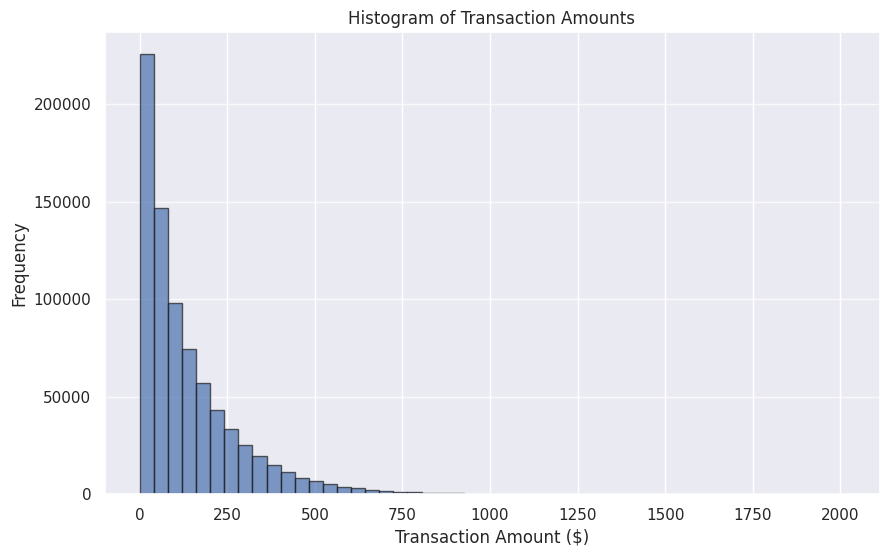

In [31]:
# Plot histogram for transactionAmount
plt.figure(figsize=(10, 6))
plt.hist(transactions['transactionAmount'], bins=50, edgecolor='k', alpha=0.7)
plt.title('Histogram of Transaction Amounts')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# Model

I first take a copy of the data and do the further steps on the copy data.

In [32]:
# Make a copy of the original data
transactions_copy = transactions.copy()

Change columns with the boolean type to 0 and 1

Also, I drop the columns which I will not use during the model training.

## Reason to move each columns:


*   ```cardLast4Digits```:This feature is a numeric identifier but has no predictive power for fraud detection.
*   ```merchantName```:This is a categorical feature with potentially many unique values (high cardinality). Including it would increase model complexity without offering much predictive value, as fraud detection is likely not tied directly to the merchant's name.
*   ```accountOpenDate```:This is a date column, and its raw format is not directly interpretable by the model.
*   ```transactionDateTime```:This raw timestamp is not useful.
*   ```currentExpDate```:This indicates when a card expires.
*   ```customerId```:This is a unique identifier for customers and does not carry predictive information for fraud detection.
*   ```dateOfLastAddressChange```:This raw date likely doesn't contribute to fraud detection.
*   ```accountNumber```:This is a unique identifier for accounts, similar to ```customerId```. Including it would not help in finding meaningful patterns.
*   ```enteredCVV``` and ```cardCVV```:The ```cvv_mismatch``` feature already captures whether the entered CVV matches the actual CVV, so these columns are redundant.
*   ```transactionDate```:This raw date column provides little predictive value.
*   ```transactionHour```:This raw date column provides little predictive value.

In [33]:
for col in ['cardPresent', 'cvv_mismatch', 'expirationDateKeyInMatch', 'isFraud']:
    transactions_copy[col] = transactions_copy[col].replace({False: 0, True: 1})

account_number = transactions_copy['accountNumber']

transactions_copy.drop(['cardLast4Digits',
         'merchantName',
         'accountOpenDate',
         'transactionDateTime',
         'currentExpDate',
         'customerId',
         'dateOfLastAddressChange',
         'accountNumber',
         'enteredCVV',
         'cardCVV',
         'transactionDate',
         'transactionHour'
         ], inplace=True, axis=1)

<ipython-input-33-c810b6111343>:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  transactions_copy[col] = transactions_copy[col].replace({False: 0, True: 1})


In [34]:
transactions_copy.isnull().sum()

,0
creditLimit,0
availableMoney,0
transactionAmount,0
acqCountry,4562
merchantCountryCode,724
posEntryMode,4054
posConditionCode,409
merchantCategoryCode,0
transactionType,698
currentBalance,0


In [35]:
transactions_copy.head(5)

,creditLimit,availableMoney,transactionAmount,acqCountry,merchantCountryCode,posEntryMode,posConditionCode,merchantCategoryCode,transactionType,currentBalance,cardPresent,expirationDateKeyInMatch,isFraud,cvv_mismatch
0,5000,5000.0,98.55,US,US,02,01,rideshare,PURCHASE,0.0,0,0,0,0
1,5000,5000.0,74.51,US,US,09,01,entertainment,PURCHASE,0.0,1,0,0,0
2,5000,5000.0,7.47,US,US,09,01,mobileapps,PURCHASE,0.0,0,0,0,0
3,5000,5000.0,7.47,US,US,09,01,mobileapps,PURCHASE,0.0,0,0,0,0
4,5000,5000.0,71.18,US,US,02,01,fastfood,PURCHASE,0.0,1,0,0,0


Install and import necessary packages

In [36]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.9/153.9 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.0/199.0 MB 5.3 MB/s eta 0:00:00


In [37]:
!pip install imblearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.3/258.3 kB 4.2 MB/s eta 0:00:00


In [38]:
import os
import pickle
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, accuracy_score
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress the ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

During my exploratory data analysis, I observed that the dataset is highly imbalanced, with significantly fewer fraudulent transactions compared to non-fraudulent ones. This imbalance can lead to biased model performance, where the model predominantly predicts the majority class. To address this, I applied random undersampling, a technique that reduces the size of the majority class to match the size of the minority class. This ensures balanced classes, enabling the model to learn patterns from both classes effectively and improving its ability to detect fraudulent transactions.
(https://semaphoreci.com/blog/imbalanced-data-machine-learning-python)

In [39]:
# Perform random undersampling to balance classes
rus = RandomUnderSampler(random_state=42)
y = transactions_copy['isFraud']
transactions_copy.drop('isFraud', inplace=True, axis=1)
balanced_x, balanced_y = rus.fit_resample(transactions_copy, y)
print(f'Before Random Under Sampling: {transactions_copy.shape}')
print(f'After Random Under Sampling: {balanced_x.shape}')

Before Random Under Sampling: (786363, 13)
After Random Under Sampling: (24834, 13)


Then I split the data into training and test sets using an 80-20 split. This ensures the model is trained on a majority of the data while retaining a separate subset for evaluating its performance.

Next, I applied a preprocessing pipeline to prepare the data for model training. Categorical features such as ```merchantCountryCode```, ```merchantCategoryCode```, ```posConditionCode```, ```posEntryMode```, ```transactionType```, and ```acqCountry``` were handled through a two-step
process:

*   **Imputation**: Missing values in categorical features were filled using the most frequent category, ensuring no data was lost due to missing entries.
*   **One-Hot Encoding**: Categorical features were converted into binary indicator variables, allowing the model to process them effectively.

Finally, the pipeline was applied to transform both the training and test datasets. This preprocessing step standardizes the input data and ensures that the model can handle categorical variables appropriately, leading to better generalization and performance.

In [40]:
# Train-test split
x_train, x_test, y_train, y_test = train_test_split(balanced_x, balanced_y, test_size=0.2, random_state=42)

# Preprocessing pipeline
pipeline = ColumnTransformer([
    ('cat_pipe', Pipeline([
        ('cat_imputer', SimpleImputer(strategy='most_frequent')),
        ('one_hot', OneHotEncoder(handle_unknown='ignore'))
    ]), ['merchantCountryCode', 'merchantCategoryCode', 'posConditionCode',
         'posEntryMode', 'transactionType', 'acqCountry']),
], remainder='passthrough')

# Transform data
x_train = pipeline.fit_transform(x_train)
x_test = pipeline.transform(x_test)

Also, I define functions to plot the confusion matrix and the ROC curve

In [41]:
def plot_confusion_matrix(y_true, y_pred, model_name="Model"):
    """
    Plots the confusion matrix as a heatmap with enhanced formatting.
    """
    conf = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        conf,
        annot=True,
        fmt="g",
        cmap="coolwarm",
        cbar=True,
        xticklabels=["Not Fraud", "Fraud"],
        yticklabels=["Not Fraud", "Fraud"],
        linewidths=0.5,
        linecolor="black",
    )
    plt.title(f"{model_name} - Confusion Matrix\nAccuracy: {acc:.2f}")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.tight_layout()
    plt.show()


def plot_combined_roc(models):
    """
    Plots the ROC curves for multiple models with better visual enhancements.
    """
    plt.figure(figsize=(10, 8))
    for model_name, (y_true, y_prob) in models.items():
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        sns.lineplot(x=fpr, y=tpr, label=f"{model_name} (AUC = {np.trapz(tpr, fpr):.2f})")

    # Diagonal line for random guessing
    plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Guessing")

    plt.title("ROC Curve Comparison")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

```roc_data``` was used to store the result for different model and plot the ROC curve an the end.

In [42]:
# Dictionary to store ROC data for all models
roc_data = {}

I will use GridSearch to find the best hyperparameters for each model, and I will show my GridSearchCV setting. For simplify, I will just run each model with the best hyperparameters combination.

## Decision Tree

### Hyperparameters for GridSearchCV
```dt_params = {
    'max_depth': [3, 5, 7],
    'min_samples_leaf': [1, 3, 5, 7],
    'max_leaf_nodes': [None, 3, 5, 7]
}```

Decision Tree Best Parameters: {'max_depth': 7, 'max_leaf_nodes': None, 'min_samples_leaf': 5}


Decision Tree Evaluation:
              precision    recall  f1-score   support

           0       0.68      0.74      0.71      2507
           1       0.71      0.64      0.68      2460

    accuracy                           0.69      4967
   macro avg       0.69      0.69      0.69      4967
weighted avg       0.69      0.69      0.69      4967



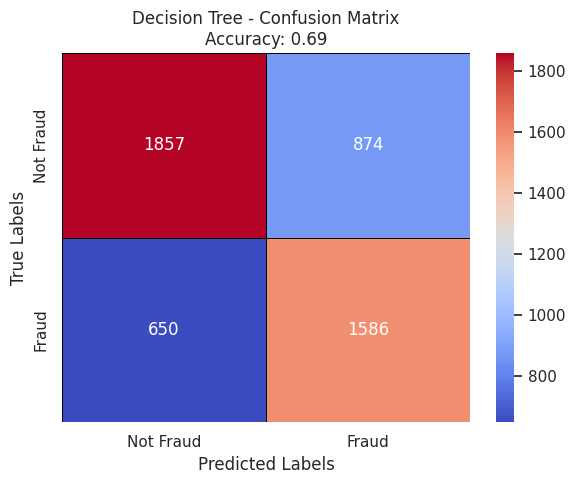

In [43]:
# Initialize the Decision Tree Classifier with the best parameters
dt_model = DecisionTreeClassifier(max_depth=7, max_leaf_nodes=None, min_samples_leaf=5)

# Fit the model
dt_model.fit(x_train, y_train)

# Evaluation
dt_predictions = dt_model.predict(x_test)

# Get predicted probabilities for the positive class
dt_probabilities = dt_model.predict_proba(x_test)[:, 1]

# Save ROC data for Decision Tree
roc_data = {"Decision Tree": (y_test, dt_probabilities)}

# Print evaluation metrics
print("\nDecision Tree Evaluation:")
print(classification_report(y_test, dt_predictions))

# Plot confusion matrix
plot_confusion_matrix(dt_predictions, y_test, model_name="Decision Tree")



*   The Decision Tree model achieves moderate accuracy (69%) with a slight bias towards identifying Not Fraud over Fraud.
*   Improvements in recall for the Fraud class are essential to reduce missed fraudulent cases.
*   The confusion matrix highlights areas where the model can improve, particularly in reducing False Negatives.



## Logistic Regression

### Hyperparameters for GridSearchCV
```lr_params = {
    'penalty': ['l1', 'l2', 'elasticnet'],  # Regularization type
    'C': [0.01, 0.1, 1, 10],   # Inverse regularization strength
    'fit_intercept': [True, False]  # Whether to include an intercept
}```

Logistic Regression Best Parameters: {'C': 0.01, 'fit_intercept': True, 'penalty': 'l2'}


Logistic Regression Evaluation:
              precision    recall  f1-score   support

           0       0.69      0.70      0.70      2507
           1       0.69      0.69      0.69      2460

    accuracy                           0.69      4967
   macro avg       0.69      0.69      0.69      4967
weighted avg       0.69      0.69      0.69      4967



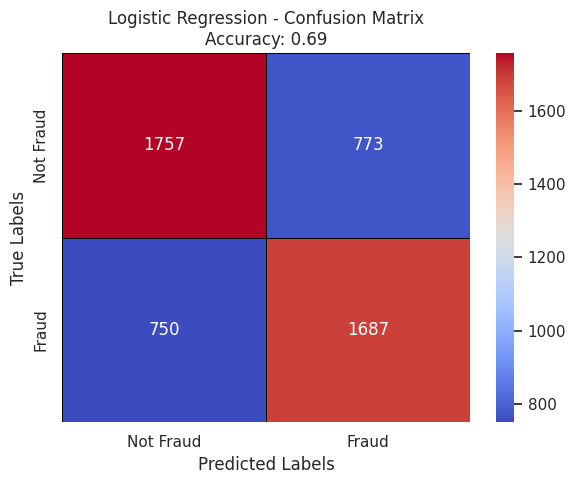

In [44]:
# Fit model with the best hyperparameters
lr_grid = lr_model = LogisticRegression(C=0.01, fit_intercept=True, penalty='l2', max_iter=1000)

# Fit the model
lr_grid.fit(x_train, y_train)

# Make predictions
lr_predictions = lr_grid.predict(x_test)

# Get predicted probabilities for the positive class
lr_probabilities = lr_grid.predict_proba(x_test)[:, 1]

# Store ROC data
roc_data["Logistic Regression"] = (y_test, lr_probabilities)

# Print evaluation metrics
print("\nLogistic Regression Evaluation:")
print(classification_report(y_test, lr_predictions))

# Plot confusion matrix
plot_confusion_matrix(lr_predictions, y_test, model_name="Logistic Regression")


*   Logistic Regression performs moderately well, achieving a balance between precision and recall for both classes.
*   It achieves 69% accuracy and identifies 69% of fraudulent transactions but still misses a significant number of fraud cases.
*   Further improvements, such as advanced models or threshold tuning, are recommended to enhance fraud detection performance.

## Random Forest

### Hyperparameters for GridSearchCV
```rf_params = {
    'n_estimators': [50, 100, 200],      # Number of trees in the forest
    'max_depth': [1, 3, 5],     # Maximum depth of the trees
    'min_samples_split': [2, 5, 10],    # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],      # Minimum samples required at a leaf node
    'bootstrap': [True, False]          # Whether to bootstrap samples
}```

Random Forest Best Parameters: {'bootstrap': True, 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}


Random Forest Evaluation:
              precision    recall  f1-score   support

           0       0.68      0.72      0.70      2507
           1       0.70      0.66      0.68      2460

    accuracy                           0.69      4967
   macro avg       0.69      0.69      0.69      4967
weighted avg       0.69      0.69      0.69      4967



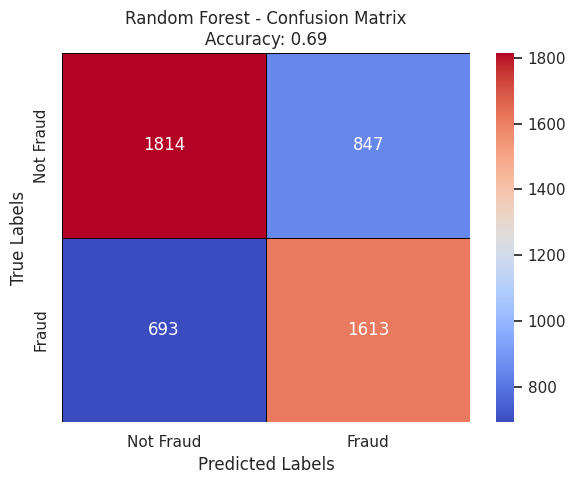

In [45]:
# Build model with the best hyperparameters
rf_grid = RandomForestClassifier(
    bootstrap=True,
    max_depth=5,
    min_samples_leaf=4,
    min_samples_split=10,
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Fit the model
rf_grid.fit(x_train, y_train)

# Make predictions
rf_predictions = rf_grid.predict(x_test)

# Get predicted probabilities for the positive class
rf_probabilities = rf_grid.predict_proba(x_test)[:, 1]

# Store ROC data
roc_data["Random Forest"] = (y_test, rf_probabilities)

# Print evaluation metrics
print("\nRandom Forest Evaluation:")
print(classification_report(y_test, rf_predictions))

# Plot confusion matrix
plot_confusion_matrix(rf_predictions, y_test, model_name="Random Forest")

*   The Random Forest model achieves 69% accuracy and has better precision and recall compared to earlier models.
*   It correctly identifies 1613 fraudulent transactions but still misses 693 fraud cases.
*   The use of 200 trees and regularization hyperparameters balances performance and prevents overfitting.

## XGBoost

### Hyperparameters for GridSearchCV
xgb_params = {
    'n_estimators': [50, 75, 100, 125, 150, 175, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

XGBoost Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150, 'subsample': 0.8}

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.



XGBoost Evaluation:
              precision    recall  f1-score   support

           0       0.72      0.72      0.72      2507
           1       0.72      0.71      0.71      2460

    accuracy                           0.72      4967
   macro avg       0.72      0.72      0.72      4967
weighted avg       0.72      0.72      0.72      4967



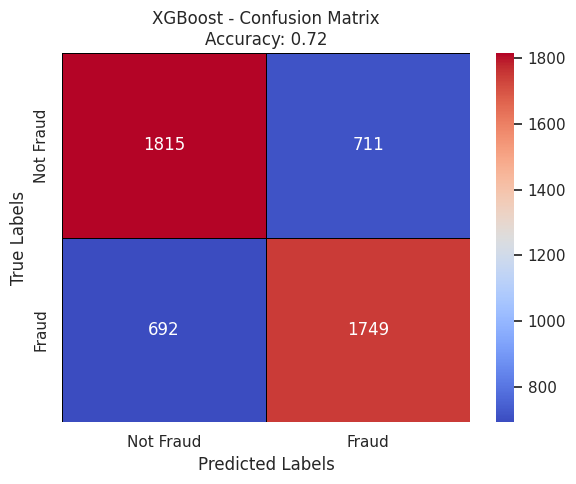

In [46]:
import tensorflow as tf
# Build model with the best hyperparameters
xgb_grid = XGBClassifier(
    colsample_bytree=1.0,
    learning_rate=0.1,
    max_depth=5,
    n_estimators=150,
    subsample=0.8,
    tree_method='gpu_hist' if tf.test.is_gpu_available() else 'auto',  # Use GPU if available
    random_state=42
)

# Fit the model
xgb_grid.fit(x_train, y_train)

# Make predictions
xgb_predictions = xgb_grid.predict(x_test)

# Get predicted probabilities for the positive class
xgb_probabilities = xgb_grid.predict_proba(x_test)[:, 1]

# Store ROC data
roc_data["XGBoost"] = (y_test, xgb_probabilities)

# Print evaluation metrics
print("\nXGBoost Evaluation:")
print(classification_report(y_test, xgb_predictions))

# Plot confusion matrix
plot_confusion_matrix(xgb_predictions, y_test, model_name="XGBoost")

*   XGBoost achieves the best overall performance with 72% accuracy and balanced precision/recall metrics.
*   It identifies 1749 fraudulent transactions while missing 692 cases.

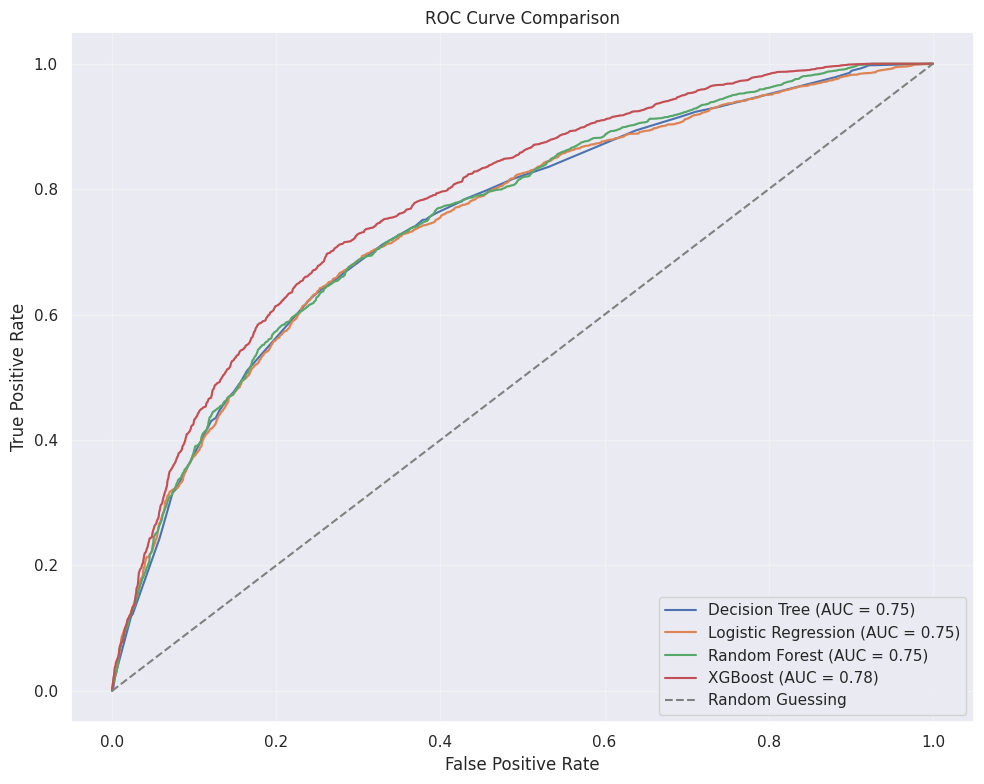

In [47]:
plot_combined_roc(roc_data)



1.   **XGBoost (AUC = 0.78)**:


*   XGBoost achieves the highest AUC of 0.78, outperforming all other models.
*   This model consistently identifies more True Positives at lower False Positive Rates compared to others, indicating its ability to effectively separate fraudulent from non-fraudulent transactions.
*   XGBoost is the most promising model for this task, making it the best candidate for deployment


2.   **Decision Tree, Logistic Regression, and Random Forest (AUC = 0.75)**:


*   These three models show very similar AUC values of 0.75, indicating comparable predictive power.
*   Random Forest slightly edges out Decision Tree and Logistic Regression at certain FPRs due to its ensemble nature, which captures more complex patterns.
*   Decision Tree and Logistic Regression models might struggle with capturing non-linear relationships compared to ensemble models like Random Forest and XGBoost.




### Adjust XGBoost

I come up with idea that I can adjust the classification threshold (default 0.5) to minimize False Negatives.

This adjust depending on the importance of detecting fraud over reducing False Positives.


XGBoost Evaluation with Adjusted Threshold (0.4):
              precision    recall  f1-score   support

           0       0.76      0.57      0.65      2507
           1       0.65      0.82      0.73      2460

    accuracy                           0.69      4967
   macro avg       0.71      0.69      0.69      4967
weighted avg       0.71      0.69      0.69      4967



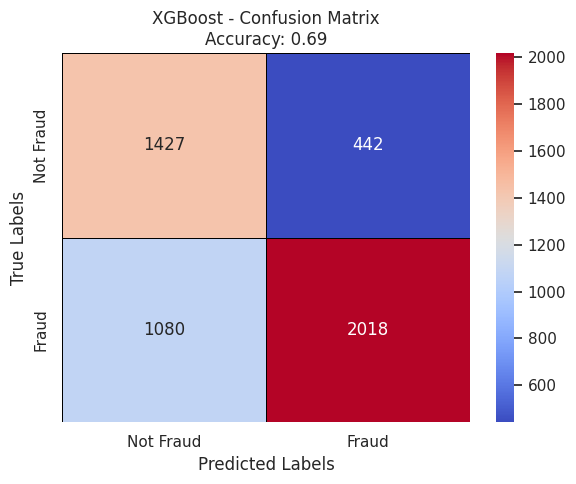

In [48]:
# Adjust threshold
threshold = 0.4  # Lower threshold to improve fraud detection
adjusted_predictions = (xgb_probabilities > threshold).astype(int)
print("\nXGBoost Evaluation with Adjusted Threshold (0.4):")
print(classification_report(y_test, adjusted_predictions))
plot_confusion_matrix(adjusted_predictions, y_test, model_name="XGBoost")



*   Recall for Fraud Detection improved to 82%, meaning the model catches most fraudulent transactions.
*   Precision for Fraud decreased to 65%, indicating a higher rate of false alarms.
*   The adjusted threshold results in a tradeoff, prioritizing fraud detection over minimizing false alarms.



# What I would do next with more time

1.   **Advanced Feature Engineering**:

*   Create new features like transaction frequency, average transaction amount, and time intervals between transactions.
*   Engineer anomaly indicators (e.g., unusually high transaction amounts).

2.   **Threshold Optimization**:

*   Adjust the classification threshold based on the trade-off between minimizing False Negatives (missed fraud) and False Positives (flagged legitimate transactions).

3.   **Handling Data Imbalance**:

*   Use techniques like SMOTE to oversample the minority class or explore cost-sensitive learning to prioritize fraud detection.

4.   **Model Interpretability and Explainability**:

*   Use tools like SHAP or LIME to explain the model's decisions and understand which features contribute most to fraud detection.
5.   **Real-Time Fraud Detection**:

*   Build and test a real-time fraud detection pipeline using tools like Apache Kafka, TensorFlow Serving, or Flask for immediate decision-making on incoming transactions.







